## Load G2CP results

In [2]:
import os
import pandas as pd
from glob import glob
from pathlib import Path
from tqdm import tqdm
import concurrent.futures

import collections
import dataclasses
import json

import google.protobuf.json_format as protobuf_json
import wandb
from wandb.proto import wandb_internal_pb2


@dataclasses.dataclass(frozen=True)
class WeightsAndBiasesDatabase:
    history:    tuple = ()
    summary:    tuple = ()
    output:     tuple = ()
    config:     tuple = ()
    files:      tuple = ()
    stats:      tuple = ()
    artifact:   tuple = ()
    tbrecord:   tuple = ()
    alert:      tuple = ()
    telemetry:  tuple = ()
    metric:     tuple = ()
    output_raw: tuple = ()
    run:        tuple = ()
    exit:       tuple = ()
    final:      tuple = ()
    header:     tuple = ()
    footer:     tuple = ()
    preempting: tuple = ()
    noop_link_artifact: tuple = ()
    use_artifact:       tuple = ()
    request:    tuple = ()

def load_wandb_database(path: str) -> WeightsAndBiasesDatabase:
    """
    读取 .wandb 文件，返回所有记录，按 record_type 分类存储。
    """
    d = collections.defaultdict(list)

    ds = wandb.sdk.internal.datastore.DataStore()
    ds.open_for_scan(path)

    while True:
        record_bin = ds.scan_data()
        if record_bin is None:
            break

        record_pb = wandb_internal_pb2.Record()
        record_pb.ParseFromString(record_bin)

        record_type = record_pb.WhichOneof("record_type")
        if record_type is None:
            continue

        record_dict = protobuf_json.MessageToDict(
            record_pb,
            preserving_proto_field_name=True,
        )

        data_dict = record_dict[record_type]

        for field, items in list(data_dict.items()):
            if isinstance(items, list) and items and "value_json" in items[0]:
                mapping = {}
                for item in items:
                    key = item.get("key") or "/".join(item.get("nested_key", []))
                    mapping[key] = json.loads(item["value_json"])
                data_dict[field] = mapping

        d[record_type].append(data_dict)

    return WeightsAndBiasesDatabase(**d)


### cross pretrain-finetune exps

In [3]:
base_dir = "../G2CP/saved_models/LINCS_cpf"

def parse_wandb_file(wandb_file):
    file = Path(wandb_file)
    try:
        db = load_wandb_database(wandb_file)
        if not db.summary:
            return None

        summary = db.summary[0]['update'] if isinstance(db.summary, list) else db.summary
        run = db.run
        run_name = run[0].get("display_name", None)

        parts = wandb_file.split('/')
        cell_line = parts[-5].split('-')[-1]
        exp_name = parts[-4]
        model = exp_name.split('_')[-4]
        seed = exp_name.split('_')[-3]
        pretrain_frac = exp_name.split('_')[-2]
        finetune_frac = exp_name.split('_')[-1]

        return {
            "run": run_name,
            "test_mse": summary.get("test_mse", None),
            "test_pearson": summary.get("test_pearson", None),
            "model": model,
            "seed": int(seed),
            "pretrain_frac": float(pretrain_frac),
            "finetune_frac": float(finetune_frac),
            "cell_line": cell_line
        }
    except Exception as e:
        print(f"❌ 读取失败: {wandb_file} ({e})")
        return None


wandb_files = glob(f"{base_dir}/**/latest-run/*.wandb", recursive=True)
records = []
with concurrent.futures.ProcessPoolExecutor(max_workers=os.cpu_count()//2) as executor:
    for result in tqdm(executor.map(parse_wandb_file, wandb_files), total=len(wandb_files)):
        if result:
            records.append(result)

all_res = pd.DataFrame(records).set_index("run").drop_duplicates()

100%|██████████| 2925/2925 [00:10<00:00, 286.67it/s]


In [4]:
pd.crosstab(all_res['pretrain_frac'], all_res['finetune_frac'])

finetune_frac,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
pretrain_frac,,,,,,,,,
0.0,75,75,75,75,75,75,75,75,75
0.1,25,25,25,25,25,25,25,25,25
0.2,25,25,25,25,25,25,25,25,25
0.3,25,25,25,25,25,25,25,25,25
0.4,25,25,25,25,25,25,25,25,25
0.5,25,25,25,25,25,25,25,25,25
0.6,25,25,25,25,25,25,25,25,25
0.7,25,25,25,25,25,25,25,25,25
0.8,25,25,25,25,25,25,25,25,25


In [5]:
import pandas as pd

all_res.to_csv('../G2CP/results/LINCS_cross_pretrain_finetune_results.csv')


### context-integrated (pooled) pretrain

In [6]:
import os
import pandas as pd
from glob import glob
from pathlib import Path
from tqdm import tqdm
import concurrent.futures

base_dir = "../G2CP/saved_models/LINCS_pool/"

def parse_wandb_file(wandb_file):
    file = Path(wandb_file)
    try:
        db = load_wandb_database(wandb_file)
        if not db.summary:
            return None

        summary = db.summary[0]['update'] if isinstance(db.summary, list) else db.summary
        run = db.run
        run_name = run[0].get("display_name", None)
        

        parts = wandb_file.split('/')
        cell_line = parts[-5].split('-')[-1]
        exp_name = parts[-4]
        model = exp_name.split('_')[-3]
        seed = exp_name.split('_')[-2]
        # pretrain_frac = exp_name.split('_')[-2]
        finetune_frac = exp_name.split('_')[-1]

        return {
            "run": run_name,
            "test_mse": summary.get("test_mse", None),
            "test_pearson": summary.get("test_pearson", None),
            "model": model,
            "seed": int(seed),
            # "pretrain_frac": float(pretrain_frac),
            "finetune_frac": float(finetune_frac),
            "cell_line": cell_line
        }
    except Exception as e:
        print(f"❌ 读取失败: {wandb_file} ({e})")
        return None


wandb_files = glob(f"{base_dir}/**/latest-run/*.wandb", recursive=True)

records = []
with concurrent.futures.ProcessPoolExecutor(max_workers=os.cpu_count()//2) as executor:
    for result in tqdm(executor.map(parse_wandb_file, wandb_files), total=len(wandb_files)):
        if result:
            records.append(result)

all_res = pd.DataFrame(records).set_index("run").drop_duplicates()

100%|██████████| 225/225 [00:00<00:00, 572.10it/s]


In [7]:
pd.crosstab(all_res['cell_line'], all_res['finetune_frac'])

finetune_frac,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
cell_line,,,,,,,,,
A375,5,5,5,5,5,5,5,5,5
A549,5,5,5,5,5,5,5,5,5
HT29,5,5,5,5,5,5,5,5,5
MCF7,5,5,5,5,5,5,5,5,5
PC3,5,5,5,5,5,5,5,5,5


In [8]:
import pandas as pd

all_res.to_csv('../G2CP/results/LINCS_context_integrated_pretrain_results.csv')


### gene essentiality-based pretrain 

In [9]:
import os
import pandas as pd
from glob import glob
from pathlib import Path
from tqdm import tqdm
import concurrent.futures

base_dir = "../G2CP/saved_models/LINCS_essp"

def parse_wandb_file(wandb_file):
    file = Path(wandb_file)
    try:
        db = load_wandb_database(wandb_file)
        if not db.summary:
            return None

        summary = db.summary[0]['update'] if isinstance(db.summary, list) else db.summary
        run = db.run
        run_name = run[0].get("display_name", None)

        parts = wandb_file.split('/')
        cell_line = parts[-5].split('-')[-1]
        exp_name = parts[-4]
        model = exp_name.split('_')[-4]
        seed = exp_name.split('_')[-3]
        pretrain_frac = exp_name.split('_')[-2]
        finetune_frac = exp_name.split('_')[-1]

        return {
            "run": run_name,
            "test_mse": summary.get("test_mse", None),
            "test_pearson": summary.get("test_pearson", None),
            "model": model,
            "seed": int(seed),
            "pretrain_frac": float(pretrain_frac),
            "finetune_frac": float(finetune_frac),
            "cell_line": cell_line
        }
    except Exception as e:
        print(f"❌ 读取失败: {wandb_file} ({e})")
        return None


wandb_files = glob(f"{base_dir}/**/latest-run/*.wandb", recursive=True)

records = []
with concurrent.futures.ProcessPoolExecutor(max_workers=os.cpu_count()//2) as executor:
    for result in tqdm(executor.map(parse_wandb_file, wandb_files), total=len(wandb_files)):
        if result:
            records.append(result)

all_res = pd.DataFrame(records).set_index("run").drop_duplicates()

100%|██████████| 450/450 [00:01<00:00, 237.50it/s]


In [10]:
all_res[['model_type', 'data_splt']] = all_res['model'].str.extract(r'^(.*?)-(essp-\w+)$')
all_res

,test_mse,test_pearson,model,seed,pretrain_frac,finetune_frac,cell_line,model_type,data_splt
run,,,,,,,,,
essp_pretrain-finetune-essp-dep_229_0.5_0.5_LINCS_essp_1029,1.508424,0.147560,pretrain-finetune-essp-dep,229,0.5,0.5,PC3,pretrain-finetune,essp-dep
essp_pretrain-finetune-essp-dep_229_0.5_0.7_LINCS_essp_1029,1.535115,0.143610,pretrain-finetune-essp-dep,229,0.5,0.7,PC3,pretrain-finetune,essp-dep
essp_pretrain-finetune-essp-udep_52_0.5_0.6_LINCS_essp_1029,1.528768,0.144985,pretrain-finetune-essp-udep,52,0.5,0.6,PC3,pretrain-finetune,essp-udep
essp_pretrain-finetune-essp-dep_564_0.5_0.3_LINCS_essp_1029,1.555452,0.144459,pretrain-finetune-essp-dep,564,0.5,0.3,PC3,pretrain-finetune,essp-dep
essp_pretrain-finetune-essp-udep_1310_0.5_0.2_LINCS_essp_1029,1.541020,0.126961,pretrain-finetune-essp-udep,1310,0.5,0.2,PC3,pretrain-finetune,essp-udep
...,...,...,...,...,...,...,...,...,...
essp_pretrain-finetune-essp-dep_52_0.5_0.4_LINCS_essp_1029,2.266330,0.142781,pretrain-finetune-essp-dep,52,0.5,0.4,A375,pretrain-finetune,essp-dep
essp_pretrain-finetune-essp-udep_229_0.5_0.4_LINCS_essp_1029,2.328120,0.127118,pretrain-finetune-essp-udep,229,0.5,0.4,A375,pretrain-finetune,essp-udep
essp_pretrain-finetune-essp-dep_564_0.5_0.6_LINCS_essp_1029,2.264254,0.140161,pretrain-finetune-essp-dep,564,0.5,0.6,A375,pretrain-finetune,essp-dep


In [11]:
pd.crosstab(all_res['model'], all_res['cell_line'])

cell_line,A375,A549,HT29,MCF7,PC3
model,,,,,
pretrain-finetune-essp-dep,45,45,45,45,45
pretrain-finetune-essp-udep,45,45,45,45,45


In [12]:
pd.crosstab(all_res['pretrain_frac'], all_res['finetune_frac'])

finetune_frac,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
pretrain_frac,,,,,,,,,
0.5,50,50,50,50,50,50,50,50,50


In [13]:
pd.crosstab(all_res['cell_line'], all_res['seed'])

seed,52,229,564,1310,1519
cell_line,,,,,
A375,18,18,18,18,18
A549,18,18,18,18,18
HT29,18,18,18,18,18
MCF7,18,18,18,18,18
PC3,18,18,18,18,18


In [14]:
import pandas as pd

all_res.to_csv('../G2CP/results/LINCS_gene_essentiality_pretrain_results.csv')


### compound similarity-based finetune 

In [15]:
base_dir = "../G2CP/saved_models/LINCS_simf"

def parse_wandb_file(wandb_file):
    file = Path(wandb_file)
    try:
        db = load_wandb_database(wandb_file)
        if not db.summary:
            return None

        summary = db.summary[0]['update'] if isinstance(db.summary, list) else db.summary
        run = db.run
        run_name = run[0].get("display_name", None)

        parts = wandb_file.split('/')
        cell_line = parts[-5].split('-')[-1]
        exp_name = parts[-4]
        model = exp_name.split('_')[-4]
        seed = exp_name.split('_')[-3]
        pretrain_frac = exp_name.split('_')[-2]
        finetune_frac = exp_name.split('_')[-1]

        return {
            "run": run_name,
            "test_mse": summary.get("test_mse", None),
            "test_pearson": summary.get("test_pearson", None),
            "model": model,
            "seed": int(seed),
            "pretrain_frac": float(pretrain_frac),
            "finetune_frac": float(finetune_frac),
            "cell_line": cell_line
        }
    except Exception as e:
        print(f"❌ 读取失败: {wandb_file} ({e})")
        return None


wandb_files = glob(f"{base_dir}/**/latest-run/*.wandb", recursive=True)

records = []
with concurrent.futures.ProcessPoolExecutor(max_workers=os.cpu_count()//2) as executor:
    for result in tqdm(executor.map(parse_wandb_file, wandb_files), total=len(wandb_files)):
        if result:
            records.append(result)

all_res = pd.DataFrame(records).set_index("run").drop_duplicates()

100%|██████████| 2700/2700 [00:07<00:00, 346.41it/s]


In [16]:
pd.crosstab(all_res['model'], all_res['cell_line'])

cell_line,A375,A549,HT29,MCF7,PC3
model,,,,,
ground-truth-simf-butina,45,45,45,45,45
ground-truth-simf-fingerprint,45,45,45,45,45
ground-truth-simf-scaffold,45,45,45,45,45
no-perturb-simf-butina,45,45,45,45,45
no-perturb-simf-fingerprint,45,45,45,45,45
no-perturb-simf-scaffold,45,45,45,45,45
pretrain-finetune-simf-butina,90,90,90,90,90
pretrain-finetune-simf-fingerprint,90,90,90,90,90
pretrain-finetune-simf-scaffold,90,90,90,90,90


In [17]:
pd.crosstab(all_res['model'], all_res['pretrain_frac'])

pretrain_frac,0.0,1.0
model,,
ground-truth-simf-butina,225,0
ground-truth-simf-fingerprint,225,0
ground-truth-simf-scaffold,225,0
no-perturb-simf-butina,225,0
no-perturb-simf-fingerprint,225,0
no-perturb-simf-scaffold,225,0
pretrain-finetune-simf-butina,225,225
pretrain-finetune-simf-fingerprint,225,225
pretrain-finetune-simf-scaffold,225,225


In [18]:
pd.crosstab(all_res['pretrain_frac'], all_res['finetune_frac'])

finetune_frac,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
pretrain_frac,,,,,,,,,
0.0,225,225,225,225,225,225,225,225,225
1.0,75,75,75,75,75,75,75,75,75


In [19]:
import pandas as pd

all_res.to_csv('../G2CP/results/LINCS_compound_similarity_finetune_results.csv')


## Plot

In [20]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import fontManager, FontProperties
import seaborn as sns
import matplotlib.colors as mcolors

font_path = "../Helvetica.ttf"
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()

sns.set_theme(
    style="ticks",
    context="paper",
    font_scale=1.1,
    rc={
        "axes.linewidth": 0.8,
        "axes.edgecolor": "black",
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.frameon": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 2.5,
        "ytick.major.size": 2.5,
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "axes.facecolor": (0, 0, 0, 0),
    }
)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name]  
plt.rcParams["pdf.fonttype"] = 42   
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["legend.facecolor"] = "white"


In [21]:
import random

random.seed(42)
seeds = random.sample(range(1,2024),5)
seeds

[1310, 229, 52, 1519, 564]

In [22]:
datasets=('HT29', 'A375', 'A549', 'MCF7', 'PC3')     

### cross fraction of pretrain & finetune

In [23]:
import pandas as pd

lincs_cpf_res = pd.read_csv('../G2CP/results/LINCS_cross_pretrain_finetune_results.csv', index_col=0)
lincs_cpf_res

,test_mse,test_pearson,model,seed,pretrain_frac,finetune_frac,cell_line
run,,,,,,,
cpf_pretrain-finetune-cpf_52_0.8_0.9_LINCS_cpf_1029,1.423742,0.147792,pretrain-finetune-cpf,52,0.8,0.9,PC3
cpf_pretrain-finetune-cpf_564_0.5_0.9_LINCS_cpf_1029,1.428942,0.154125,pretrain-finetune-cpf,564,0.5,0.9,PC3
cpf_pretrain-finetune-cpf_564_0.7_0.5_LINCS_cpf_1029,1.535821,0.158224,pretrain-finetune-cpf,564,0.7,0.5,PC3
cpf_pretrain-finetune-cpf_229_0.1_0.1_LINCS_cpf_1029,1.536654,0.035340,pretrain-finetune-cpf,229,0.1,0.1,PC3
cpf_pretrain-finetune-cpf_1519_0.4_0.4_LINCS_cpf_1029,1.508057,0.122223,pretrain-finetune-cpf,1519,0.4,0.4,PC3
...,...,...,...,...,...,...,...
cpf_pretrain-finetune-cpf_1310_0.2_0.6_LINCS_cpf_1029,2.357196,0.058646,pretrain-finetune-cpf,1310,0.2,0.6,A375
cpf_pretrain-finetune-cpf_229_0.5_0.2_LINCS_cpf_1029,2.315386,0.129837,pretrain-finetune-cpf,229,0.5,0.2,A375
cpf_pretrain-finetune-cpf_229_0.8_0.9_LINCS_cpf_1029,2.283261,0.141715,pretrain-finetune-cpf,229,0.8,0.9,A375


In [24]:
mapping_dict = {
    'pretrain-finetune-cpf': 'pretrain-finetune',
    'no-perturb-cpf': 'no-perturb',
    'ground-truth-cpf': 'ground-truth',
    'no-pretrain': 'no-pretrain',
}
lincs_cpf_res['model'] = lincs_cpf_res['model'].map(mapping_dict) 

lincs_cpf_res.loc[
    (lincs_cpf_res['pretrain_frac'] == 0.0) & (lincs_cpf_res['model'].str.contains('pretrain-finetune', case=False)),
    'model'
] = 'no-pretrain'


lincs_cpf_res.loc[
    (lincs_cpf_res['pretrain_frac'] == 1.0) & (lincs_cpf_res['model'].str.contains('pretrain-finetune', case=False)),
    'model'
] = 'full-pretrain'


In [25]:
lincs_cpf_res.groupby(['cell_line', 'model']).mean(numeric_only = True)

test_mse  test_pearson   seed  pretrain_frac  \
cell_line model                                                             
A375      full-pretrain      2.312043      0.146517  734.8            1.0   
          ground-truth       3.166634      0.266278  734.8            0.0   
          no-perturb         2.391485      0.002070  734.8            0.0   
          no-pretrain        2.371085      0.070972  734.8            0.0   
          pretrain-finetune  2.323346      0.118080  734.8            0.5   
A549      full-pretrain      1.659097      0.141754  734.8            1.0   
          ground-truth       2.943291      0.181971  734.8            0.0   
          no-perturb         1.685987     -0.001527  734.8            0.0   
          no-pretrain        1.693055      0.102604  734.8            0.0   
          pretrain-finetune  1.654688      0.112944  734.8            0.5   
HT29      full-pretrain      2.037484      0.167965  734.8            1.0   
          ground-truth       3.542689      0.273639  734.8            0.0   
          no-perturb         2.081495      0.006162  734.8            0.0   
          no-pretrain        2.075311      0.065717  734.8            0.0   
          pretrain-finetune  2.042377      0.133499  734.8            0.5   
MCF7      full-pretrain      1.476851      0.159712  734.8            1.0   
          ground-truth       2.415272      0.183406  734.8            0.0   
          no-perturb         1.492395      0.001414  734.8            0.0   
          no-pretrain        1.490858      0.130572  734.8            0.0   
          pretrain-finetune  1.470838      0.118048  734.8            0.5   
PC3       full-pretrain      1.538813      0.149108  734.8            1.0   
          ground-truth       2.493088      0.181683  734.8            0.0   
          no-perturb         1.529274      0.007438  734.8            0.0   
          no-pretrain        1.532001      0.122872  734.8            0.0   
          pretrain-finetune  1.527429      0.120301  734.8            0.5   

                             finetune_frac  
cell_line model                             
A375      full-pretrain                0.5  
          ground-truth                 0.5  
          no-perturb                   0.5  
          no-pretrain                  0.5  
          pretrain-finetune            0.5  
A549      full-pretrain                0.5  
          ground-truth                 0.5  
          no-perturb                   0.5  
          no-pretrain                  0.5  
          pretrain-finetune            0.5  
HT29      full-pretrain                0.5  
          ground-truth                 0.5  
          no-perturb                   0.5  
          no-pretrain                  0.5  
          pretrain-finetune            0.5  
MCF7      full-pretrain                0.5  
          ground-truth                 0.5  
          no-perturb                   0.5  
          no-pretrain                  0.5  
          pretrain-finetune            0.5  
PC3       full-pretrain                0.5  
          ground-truth                 0.5  
          no-perturb                   0.5  
          no-pretrain                  0.5  
          pretrain-finetune            0.5

#### heatmap

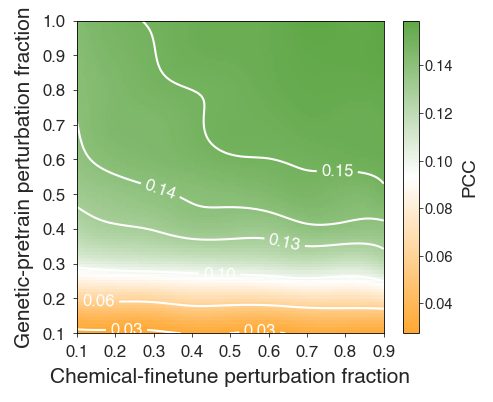

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RectBivariateSpline
from matplotlib import cm

metric = 'test_pearson'
custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ['#ffa832', "w", '#5fa746']) 

pivot = (
    lincs_cpf_res[lincs_cpf_res['pretrain_frac']!=0.0]
    .groupby(['pretrain_frac', 'finetune_frac'])[metric]
    .mean()
    .unstack()
    .sort_index(axis=0)
    .sort_index(axis=1)
)

Z = pivot.values
x = pivot.columns.values         # finetune_frac
y = pivot.index.values           # pretrain_frac

# smoothing
spline = RectBivariateSpline(y, x, Z)
n = 100
y_new = np.linspace(y.min(), y.max(), n)
x_new = np.linspace(x.min(), x.max(), n)
Y_new, X_new = np.meshgrid(y_new, x_new, indexing='ij')
Z_new = spline(y_new, x_new)  # shape = (len(y_new), len(x_new))


plt.figure(figsize=(3.4,2.8))
im = plt.imshow(Z_new, cmap=custom_cmap, origin='lower',
                extent=[x.min(), x.max(), y.min(), y.max()],
                aspect='auto'
                )
cbar = plt.colorbar(im, label="PCC")
cbar.ax.spines['outline'].set_linewidth(0.4) 
cbar.ax.tick_params(
    width=0.4,    
    length=2.0,
    direction='out',
    pad=1
)
cbar.ax.yaxis.label.set_size(9)
for t in cbar.ax.get_yticklabels():
    t.set_size(7)


levels = [0.03, 0.06, 0.10, 0.13, 0.14, 0.15, 0.16]
cs = plt.contour(X_new, Y_new, Z_new, 
                 levels=levels, colors='white', linewidths=1, alpha=1)
plt.clabel(cs, inline=True, fontsize=8, fmt="%.2f")
plt.xticks(x)
plt.yticks(y)
plt.xlabel('Chemical-finetune perturbation fraction', size=10)
plt.ylabel('Genetic-pretrain perturbation fraction', size=10)

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(0.4)    
ax.tick_params(
    width=0.4,      
    length=2.0,
    direction='out'
)
plt.tight_layout()
plt.show()

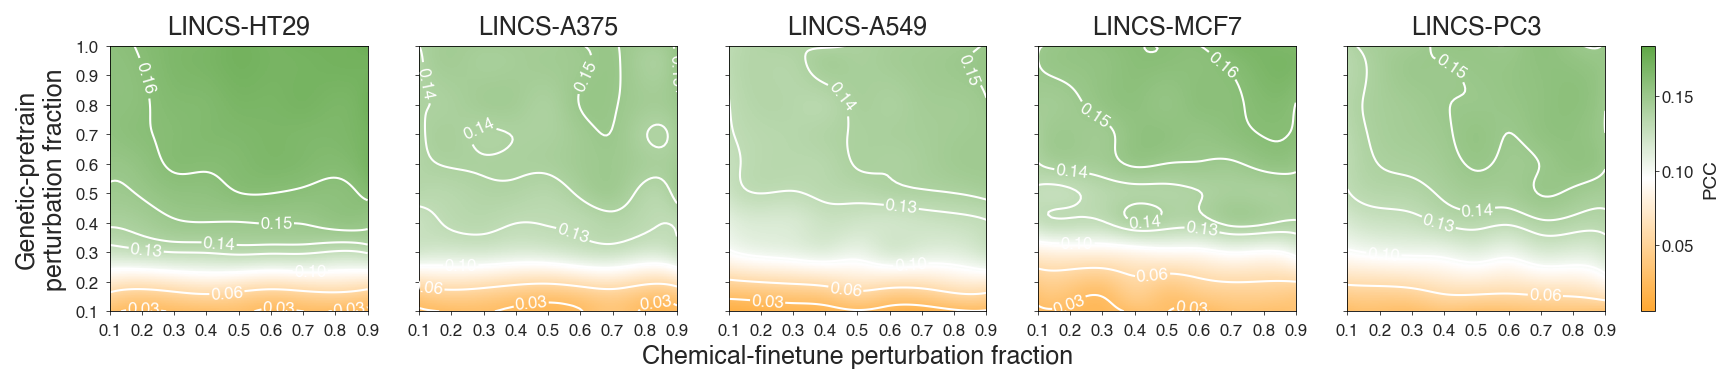

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RectBivariateSpline
from matplotlib import cm

metric = 'test_pearson'
cell_lines = ["HT29", "A375", "A549", "MCF7", "PC3"]  
custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ['#ffa832', "w", '#5fa746']) 

fig, axes = plt.subplots(1, len(cell_lines), figsize=(3.1*len(cell_lines), 2.3), sharey=True)

vmin = lincs_cpf_res[lincs_cpf_res['pretrain_frac']!=0.0][metric].min()
vmax = lincs_cpf_res[lincs_cpf_res['pretrain_frac']!=0.0][metric].max()

for ax, cell in zip(axes, cell_lines):

    pivot = (
        lincs_cpf_res[(lincs_cpf_res['cell_line']==cell) & (lincs_cpf_res['pretrain_frac']!=0.0)]
        .groupby(['pretrain_frac', 'finetune_frac'])[metric]
        .mean()
        .unstack()
        .sort_index(axis=0)
        .sort_index(axis=1)
    )

    Z = pivot.values
    x = pivot.columns.values
    y = pivot.index.values

    spline = RectBivariateSpline(y, x, Z)  
    n = 100
    y_new = np.linspace(y.min(), y.max(), n)
    x_new = np.linspace(x.min(), x.max(), n)
    Y_new, X_new = np.meshgrid(y_new, x_new, indexing="ij")
    Z_new = spline(y_new, x_new)

    im = ax.imshow(
        Z_new,
        cmap=custom_cmap,
        origin='lower',
        extent=[x.min(), x.max(), y.min(), y.max()],
        aspect='auto',
        vmin=vmin, vmax=vmax
    )
    levels = [0.03, 0.06, 0.10, 0.13, 0.14, 0.15, 0.16]
    cs = ax.contour(X_new, Y_new, Z_new, levels=levels, colors='white', linewidths=1)
    ax.clabel(cs, inline=True, fontsize=8, fmt="%.2f")

    ax.set_xticks(x)
    ax.set_yticks(y)
    ax.tick_params(width=0.4, length=2, direction='out')
    for spine in ax.spines.values():
        spine.set_linewidth(0.4)

    ax.set_title('LINCS-'+cell, fontsize=12)

axes[0].set_ylabel("Genetic-pretrain\nperturbation fraction", fontsize=12)
for ax in axes[1:]:
    ax.set_ylabel("")

axes[2].set_xlabel("Chemical-finetune perturbation fraction", fontsize=12, labelpad=3)

cbar = fig.colorbar(im, ax=axes, shrink=1, pad=0.02, label="PCC")
cbar.ax.spines['outline'].set_linewidth(0.4)
cbar.ax.tick_params(width=0.4, length=2, direction='out', pad=1.5)

# )
plt.show()

#### lineplot

In [28]:
filtered_lincs_cpf_res = lincs_cpf_res[lincs_cpf_res['pretrain_frac'].isin([0.0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]) & lincs_cpf_res['finetune_frac'].isin([0.2, 0.4, 0.6, 0.8])]

In [29]:
res = lincs_cpf_res[lincs_cpf_res['pretrain_frac'].isin([0.0, 1.0]) & lincs_cpf_res['finetune_frac'].isin([0.2])]
res = res.drop(columns=['seed'])
res[res['finetune_frac']==0.2].groupby(['cell_line', 'model']).mean()


test_mse  test_pearson  pretrain_frac  finetune_frac
cell_line model                                                              
A375      full-pretrain  2.311429      0.145611            1.0            0.2
          ground-truth   3.178661      0.267292            0.0            0.2
          no-perturb     2.386257      0.002161            0.0            0.2
          no-pretrain    2.410213      0.011658            0.0            0.2
A549      full-pretrain  1.651236      0.137518            1.0            0.2
          ground-truth   2.916560      0.181401            0.0            0.2
          no-perturb     1.680459     -0.001311            0.0            0.2
          no-pretrain    1.722839      0.019808            0.0            0.2
HT29      full-pretrain  2.051063      0.161240            1.0            0.2
          ground-truth   3.512703      0.270362            0.0            0.2
          no-perturb     2.087689      0.005867            0.0            0.2
          no-pretrain    2.109751      0.011550            0.0            0.2
MCF7      full-pretrain  1.479937      0.153123            1.0            0.2
          ground-truth   2.433929      0.181870            0.0            0.2
          no-perturb     1.500664      0.001500            0.0            0.2
          no-pretrain    1.516794      0.053383            0.0            0.2
PC3       full-pretrain  1.545226      0.144070            1.0            0.2
          ground-truth   2.496510      0.182588            0.0            0.2
          no-perturb     1.538369      0.007495            0.0            0.2
          no-pretrain    1.540895      0.059603            0.0            0.2

In [30]:
mean_results = res[res['finetune_frac']==0.2].groupby(['cell_line', 'model'])['test_pearson'].mean().unstack()
mean_results

model,full-pretrain,ground-truth,no-perturb,no-pretrain
cell_line,,,,
A375,0.145611,0.267292,0.002161,0.011658
A549,0.137518,0.181401,-0.001311,0.019808
HT29,0.161240,0.270362,0.005867,0.011550
MCF7,0.153123,0.181870,0.001500,0.053383
PC3,0.144070,0.182588,0.007495,0.059603


In [31]:
percentage_increase = ((mean_results['full-pretrain'] - mean_results['no-pretrain']) / mean_results['no-pretrain']) * 100
print(percentage_increase)

cell_line
A375    1149.066056
A549     594.270376
HT29    1296.068735
MCF7     186.837108
PC3      141.717402
dtype: float64


In [32]:
mean_results = res[res['finetune_frac']==0.2].groupby(['cell_line', 'model'])['test_pearson'].mean().unstack().mean()
mean_results

model
full-pretrain    0.148312
ground-truth     0.216703
no-perturb       0.003142
no-pretrain      0.031200
dtype: float64

In [33]:
percentage_increase = ((mean_results['full-pretrain'] - mean_results['no-pretrain']) / mean_results['no-pretrain']) * 100
print(percentage_increase)

375.3582930189256


In [34]:
all_res = filtered_lincs_cpf_res
models = ['pretrain-finetune',
            'no-pretrain',
            'no-perturb',
            'full-pretrain',
            'ground-truth']
metrics = ['test_mse', 'test_pearson']


In [35]:
df = all_res[all_res['model'].isin(models)].loc[:, metrics+['model', 'pretrain_frac', 'finetune_frac', 'cell_line']]
df['model_new'] = df.apply(
    lambda row: f"{row['pretrain_frac']:.1f}_pretrain-finetune"
    if row['model'] == 'pretrain-finetune' 
    else row['model'],
    axis=1
)
df['model_new'].unique()

array(['0.3_pretrain-finetune', 'no-pretrain', 'no-perturb',
       '0.7_pretrain-finetune', '0.5_pretrain-finetune', 'full-pretrain',
       '0.9_pretrain-finetune', '0.1_pretrain-finetune', 'ground-truth'],
      dtype=object)

In [36]:
models_new = [
    'no-perturb',
    'ground-truth',

    '0.1_pretrain-finetune',
    '0.3_pretrain-finetune',
    '0.5_pretrain-finetune',
    '0.7_pretrain-finetune',
    '0.9_pretrain-finetune',
    
    'full-pretrain',
    'no-pretrain',
    ]
    
model_colors = {
    'no-perturb': '#8b8b8b',
    'ground-truth': '#8DA0CB',

    'full-pretrain': '#4ea72e',    

    '0.9_pretrain-finetune': '#6db66d',
    '0.7_pretrain-finetune': '#88c388',
    '0.5_pretrain-finetune': '#a2d1a2',
    '0.3_pretrain-finetune': '#bfdcbf',
    '0.1_pretrain-finetune': '#d8ead8',

    'no-pretrain': '#ff9300',        
}

model_markers = {
    'no-perturb': 'X',
    'ground-truth': 'D',

    'full-pretrain': 'o',

    '0.9_pretrain-finetune': 'o',
    '0.7_pretrain-finetune': 'o',
    '0.5_pretrain-finetune': 'o',
    '0.3_pretrain-finetune': 'o',
    '0.1_pretrain-finetune': 'o',

    'no-pretrain': 's',
}

df['rank'] = df['model_new'].apply(lambda x: models_new.index(x))
df = df.sort_values(by=['rank'], ascending=True)

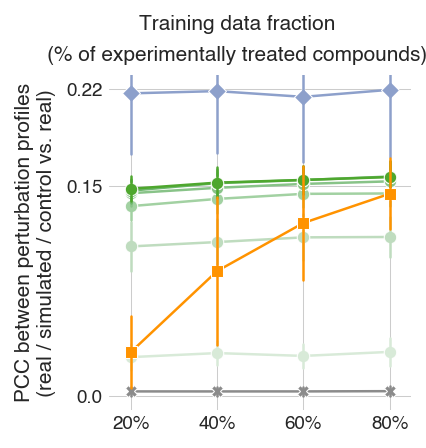

In [37]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

df_mean = (
    df.groupby(['model_new', 'pretrain_frac', 'finetune_frac'], as_index=False)
      .agg({'test_pearson':'mean'})
)

fig, ax = plt.subplots(figsize=(2.6, 2.9))

sns.lineplot(
    data=df,
    x="finetune_frac",
    y="test_pearson",
    hue="model_new",
    style="model_new",
    linewidth=1.2,
    markers=model_markers,
    markersize=6,
    markeredgewidth=0.5,
    dashes=False,
    palette=model_colors,
    ax=ax,
    legend=False,
    err_style="bars", 
    errorbar=('sd', 1),
    err_kws={"elinewidth": 1.2}, 
)


ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

ax.grid(axis='both', color='black', alpha=0.2, linewidth=0.5)

ax.tick_params(axis='y', which='major', labelsize=9, length=0, pad=3)
ax.tick_params(axis='x', which='major', labelsize=9, length=0, pad=3)

ax.set_ylim(-0.01, 0.23)
ax.set_yticks([0.0, 0.15, 0.22])
ax.set_yticklabels(['0.0', '0.15', '0.22'], fontsize=9)
ax.set_xlim(0.15, 0.85)
ax.set_xticks([0.2, 0.4, 0.6, 0.8])
ax.set_xticklabels(['20%', '40%', '60%', '80%'], fontsize=9)

ax.spines['top'].set_linewidth(0.0)
ax.spines['bottom'].set_linewidth(0.0)
ax.spines['left'].set_linewidth(0.0)
ax.spines['right'].set_linewidth(0.0)


xlabel = ax.set_xlabel("Training data fraction\n(% of experimentally treated compounds)", fontsize=10)
ax.xaxis.set_label_coords(0.425, 1.18)
xlabel.set_linespacing(1.8) 
ax.set_ylabel('PCC between perturbation profiles\n(real / simulated / control vs. real)', fontsize=10, labelpad=5)

plt.show()

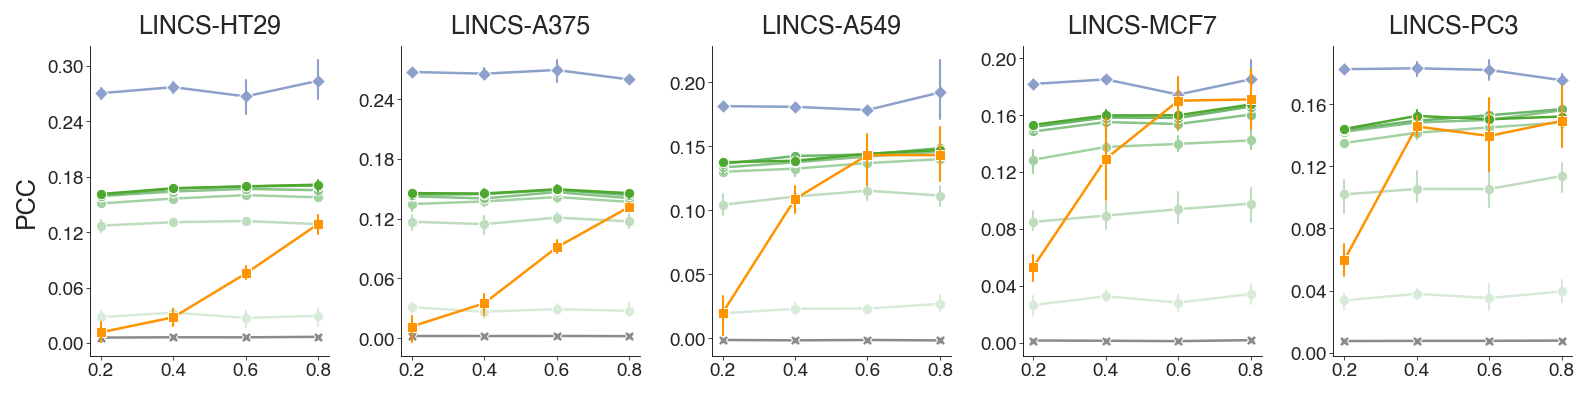

In [38]:
import pandas as pd
import numpy as np

cell_lines = ['HT29', 'A375', 'A549', 'MCF7', 'PC3']

fig, axes = plt.subplots(nrows=1, ncols=len(cell_lines), figsize=(10.7, 2.75))

if not isinstance(axes, np.ndarray):
    axes = [axes]

for ax, cell_line in zip(axes, cell_lines):
    subset_res = df[df['cell_line'] == cell_line]
    subset_res = subset_res.sort_values(by=['rank', 'pretrain_frac', 'finetune_frac'], ascending=True)
    
    sns.lineplot(
        data=subset_res,
        x="finetune_frac", 
        y="test_pearson", 
        hue="model_new",
        style="model_new",
        linewidth=1.2,
        markers=model_markers,
        markersize=5,
        markeredgewidth=0.5,
        dashes=False,
        palette=model_colors,
        err_style="bars", 
        errorbar=('ci', 95),
        err_kws={"elinewidth": 1}, 
        legend=False, 
        ax=ax
    )
    
    ax.set_title(f'LINCS-{cell_line}', fontsize=12)
    ax.set_xlabel('', fontsize=12)
    if 'HT29' in cell_line:
        ax.set_ylabel('PCC', fontsize=12)
    else:
        ax.set_ylabel('')

    ax.tick_params(axis='both', which='major', labelsize=9)
    ax.tick_params(width=0.4, length=2, direction='out', pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.4)

    from matplotlib.ticker import MaxNLocator
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.subplots_adjust(wspace=0.3)
plt.show()

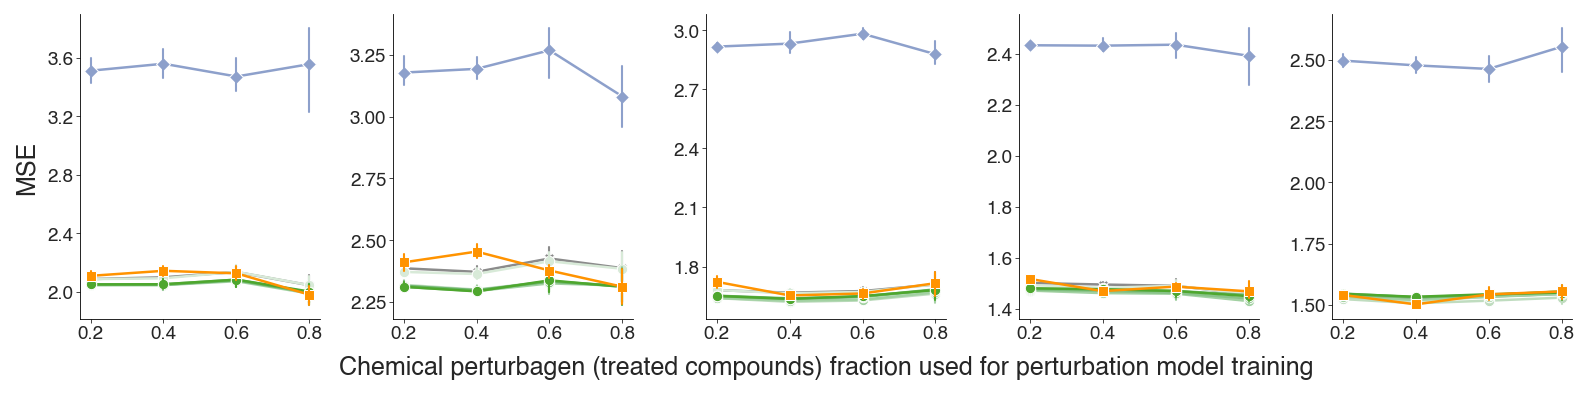

In [39]:
cell_lines = ['HT29', 'A375', 'A549', 'MCF7', 'PC3']

fig, axes = plt.subplots(nrows=1, ncols=len(cell_lines), figsize=(10.7, 2.75))

if not isinstance(axes, np.ndarray):
    axes = [axes]

for ax, cell_line in zip(axes, cell_lines):
    subset_res = df[df['cell_line'] == cell_line]
    subset_res = subset_res.sort_values(by=['rank', 'pretrain_frac', 'finetune_frac'], ascending=True)
    
    sns.lineplot(
        data=subset_res,
        x="finetune_frac", 
        y="test_mse", 
        hue="model_new",
        style="model_new",
        linewidth=1.2,
        markers=model_markers,
        markersize=5,
        markeredgewidth=0.5,
        dashes=False,
        palette=model_colors,
        err_style="bars", 
        errorbar=('ci', 95), 
        err_kws={"elinewidth": 1}, 
        legend=False, 
        ax=ax
    )
    
    ax.set_title(f'', fontsize=12)
    ax.set_xlabel('', fontsize=12)
    if 'HT29' in cell_line:
        ax.set_ylabel('MSE', fontsize=12)
    else:
        ax.set_ylabel('')

    ax.tick_params(axis='both', which='major', labelsize=9)
    ax.tick_params(width=0.4, length=2, direction='out', pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.4)

    from matplotlib.ticker import MaxNLocator
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[2].set_xlabel('Chemical perturbagen (treated compounds) fraction used for perturbation model training', fontsize=12, labelpad=6)

plt.tight_layout()
plt.subplots_adjust(wspace=0.3)

plt.show()

In [40]:
legend_models = [
    'Real vs. Control',
    'Real vs. Real',
    'Real vs. Simulated w/o genetic-pretrain',
    'Real vs. Simulated w/ full genetic-pretrain',
    '90% pretrain',
    '70% pretrain',
    '50% pretrain',
    '30% pretrain',
    '10% pretrain',
]
model_colors = {
    'Real vs. Control': 'darkgray',
    'Real vs. Real': '#8DA0CB',
    'Real vs. Simulated w/ full genetic-pretrain': '#4ea72e',
    '90% pretrain': '#6db66d',
    '70% pretrain': '#88c388',
    '50% pretrain': '#a2d1a2',
    '30% pretrain': '#bfdcbf',
    '10% pretrain': '#d8ead8',
    'Real vs. Simulated w/o genetic-pretrain': '#ff9300',
}
model_markers = {
    'Real vs. Control': 'X',
    'Real vs. Real': 'D',
    'Real vs. Simulated w/ full genetic-pretrain': 'o',
    '90% pretrain': 'o',
    '70% pretrain': 'o',
    '50% pretrain': 'o',
    '30% pretrain': 'o',
    '10% pretrain': 'o',
    'Real vs. Simulated w/o genetic-pretrain': 's',
}

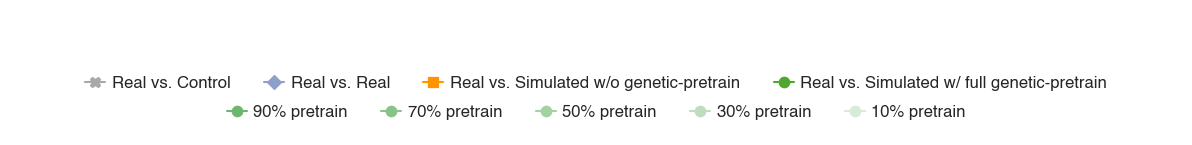

In [41]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

legend_elements = [
    Line2D(
        [0], [0],
        marker=model_markers[m],
        color=model_colors[m],
        linestyle='-',
        linewidth=1,
        markersize=6 if m == 'no-pretrain' else 5,
        markeredgewidth=0.6,
        label=m
    )
    for m in legend_models
]

legend_1 = legend_elements[:4]   
legend_2 = legend_elements[4:]   

fig, ax = plt.subplots(figsize=(10, 1.0))

leg1 = ax.legend(
    handles=legend_1,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.6),
    ncol=4,
    frameon=False,
    fontsize=8,
    handlelength=1.2,
    handletextpad=0.4,
    columnspacing=2,
)
leg2 = ax.legend(
    handles=legend_2,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.35),
    ncol=5,
    frameon=False,
    fontsize=8,
    handlelength=1.2,
    handletextpad=0.4,
    columnspacing=2,
)
ax.add_artist(leg1)
ax.axis('off')
plt.show()

### gene essentiality-based pretrain

In [42]:
import pandas as pd

lincs_essp_res = pd.read_csv('../G2CP/results/LINCS_gene_essentiality_pretrain_results.csv', index_col=0)


In [43]:
lincs_essp_res.groupby(['cell_line', 'model']).mean(numeric_only = True)

test_mse  test_pearson   seed  \
cell_line model                                                        
A375      pretrain-finetune-essp-dep   2.306195      0.145224  734.8   
          pretrain-finetune-essp-udep  2.323480      0.130509  734.8   
A549      pretrain-finetune-essp-dep   1.647569      0.131825  734.8   
          pretrain-finetune-essp-udep  1.648031      0.134611  734.8   
HT29      pretrain-finetune-essp-dep   2.030676      0.158468  734.8   
          pretrain-finetune-essp-udep  2.033742      0.156718  734.8   
MCF7      pretrain-finetune-essp-dep   1.458664      0.151346  734.8   
          pretrain-finetune-essp-udep  1.464103      0.130020  734.8   
PC3       pretrain-finetune-essp-dep   1.528011      0.142741  734.8   
          pretrain-finetune-essp-udep  1.528117      0.136229  734.8   

                                       pretrain_frac  finetune_frac  
cell_line model                                                      
A375      pretrain-finetune-essp-dep             0.5            0.5  
          pretrain-finetune-essp-udep            0.5            0.5  
A549      pretrain-finetune-essp-dep             0.5            0.5  
          pretrain-finetune-essp-udep            0.5            0.5  
HT29      pretrain-finetune-essp-dep             0.5            0.5  
          pretrain-finetune-essp-udep            0.5            0.5  
MCF7      pretrain-finetune-essp-dep             0.5            0.5  
          pretrain-finetune-essp-udep            0.5            0.5  
PC3       pretrain-finetune-essp-dep             0.5            0.5  
          pretrain-finetune-essp-udep            0.5            0.5

### context-integrated (pooled) pretrain

In [44]:
import pandas as pd

lincs_pool_res = pd.read_csv('../G2CP/results/LINCS_context_integrated_pretrain_results.csv', index_col=0)


In [45]:
lincs_pool_res.groupby(['cell_line', 'model']).mean(numeric_only = True)

,,test_mse,test_pearson,seed,finetune_frac
cell_line,model,,,,
A375,pretrain-finetune-pool,2.322245,0.143417,734.8,0.5
A549,pretrain-finetune-pool,1.661580,0.133795,734.8,0.5
HT29,pretrain-finetune-pool,2.063737,0.149885,734.8,0.5
MCF7,pretrain-finetune-pool,1.488779,0.152033,734.8,0.5
PC3,pretrain-finetune-pool,1.536414,0.151347,734.8,0.5


### integrate results

In [47]:
filtered_cpf = lincs_cpf_res[lincs_cpf_res['pretrain_frac'].isin([0.0, 0.5, 1.0])]

In [48]:
lincs_p_res = pd.concat([filtered_cpf, lincs_pool_res, lincs_essp_res], ignore_index=True)

In [49]:
pd.crosstab(lincs_p_res['model'], lincs_p_res['cell_line'])

cell_line,A375,A549,HT29,MCF7,PC3
model,,,,,
full-pretrain,45,45,45,45,45
ground-truth,45,45,45,45,45
no-perturb,45,45,45,45,45
no-pretrain,45,45,45,45,45
pretrain-finetune,45,45,45,45,45
pretrain-finetune-essp-dep,45,45,45,45,45
pretrain-finetune-essp-udep,45,45,45,45,45
pretrain-finetune-pool,45,45,45,45,45


In [50]:
pd.crosstab(lincs_p_res['model'], lincs_p_res['pretrain_frac'])

pretrain_frac,0.0,0.5,1.0
model,,,
full-pretrain,0,0,225
ground-truth,225,0,0
no-perturb,225,0,0
no-pretrain,225,0,0
pretrain-finetune,0,225,0
pretrain-finetune-essp-dep,0,225,0
pretrain-finetune-essp-udep,0,225,0


In [51]:
lincs_p_res.groupby(['model']).mean(numeric_only = True)

,test_mse,test_pearson,seed,pretrain_frac,finetune_frac
model,,,,,
full-pretrain,1.804858,0.153011,734.8,1.0,0.5
ground-truth,2.912195,0.217395,734.8,0.0,0.5
no-perturb,1.836127,0.003111,734.8,0.0,0.5
no-pretrain,1.832462,0.098547,734.8,0.0,0.5
pretrain-finetune,1.795425,0.141698,734.8,0.5,0.5
pretrain-finetune-essp-dep,1.794223,0.145921,734.8,0.5,0.5
pretrain-finetune-essp-udep,1.799495,0.137617,734.8,0.5,0.5
pretrain-finetune-pool,1.814551,0.146095,734.8,NaN,0.5


### plot

In [52]:
palette = {
    'ground-truth': '#8DA0CB',
    'no-perturb': '#8B8B8B',
    'no-pretrain': '#FF9300',

    'pretrain-finetune': '#A2D1A2',             # baseline transfer
    'pretrain-finetune-essp-dep': '#6DB66D',    # strong prior
    'pretrain-finetune-essp-udep': '#88C388',   # weaker prior

    'full-pretrain': '#4EA72E',                 # generalist
    'pretrain-finetune-pool': '#BFDCBF',        # pooled baseline
}

color_50 = "#9DCD9D"   
color_100 = "#4EA72E"  

palette = {
    'ground-truth': '#8DA0CB',
    'no-perturb': '#8B8B8B',
    'no-pretrain': '#FF9300',

    'pretrain-finetune': color_50,
    'pretrain-finetune-essp-dep': color_50,
    'pretrain-finetune-essp-udep': color_50,

    'full-pretrain': color_100,
    'pretrain-finetune-pool': color_100,
}

model_order = [
    'ground-truth',
    'no-perturb',
    'no-pretrain',
    'pretrain-finetune',
    'pretrain-finetune-essp-dep',
    'pretrain-finetune-essp-udep',
    'full-pretrain',
    'pretrain-finetune-pool',
]

model_display = {
    'ground-truth': 'Same-perturb',
    'no-perturb': 'Control vs. perturb',
    'no-pretrain': 'No genetic-pretrain',
    'pretrain-finetune': 'Random',
    'pretrain-finetune-essp-dep': 'Top-essential',
    'pretrain-finetune-essp-udep': 'Bottom-essential',
    'full-pretrain': 'Context-specific',
    'pretrain-finetune-pool': 'Context-integrated',
}

In [53]:
from scipy.stats import ttest_ind, wilcoxon
import numpy as np

pairs = [
    ('pretrain-finetune', 'pretrain-finetune-essp-dep'),   # 50% Random vs Top-ESS
    ('pretrain-finetune', 'pretrain-finetune-essp-udep'),  # 50% Random vs Bottom-ESS
    ('pretrain-finetune-essp-dep', 'pretrain-finetune-essp-udep'),  # Top-ESS vs Bottom-ESS

    ('full-pretrain', 'pretrain-finetune-pool')            # 100% Random vs Context-integrated
]

def compute_p(df, group1, group2, metric):
    v1 = df.loc[df['model'] == group1, metric].dropna().values
    v2 = df.loc[df['model'] == group2, metric].dropna().values
    
    if len(v1) == 0 or len(v2) == 0:
        return np.nan
    
    min_len = min(len(v1), len(v2))
    if len(v1) != len(v2):
        print(f"Warning: unequal lengths, truncating to {min_len} for pairing.")
        v1 = v1[:min_len]
        v2 = v2[:min_len]
    
    # Wilcoxon signed-rank test
    stat, p = wilcoxon(v1, v2, alternative='two-sided')
    return p

def p_to_star(p):
    if p < 1e-4: return "****"
    elif p < 1e-3: return "***"
    elif p < 1e-2: return "**"
    elif p < 0.05: return "*"
    else: return "ns"

/tmp/ipykernel_922779/1027337480.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_stats, x='model', y='test_pearson_mean',
/tmp/ipykernel_922779/1027337480.py:29: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['' for m in model_order], rotation=30, ha='right')


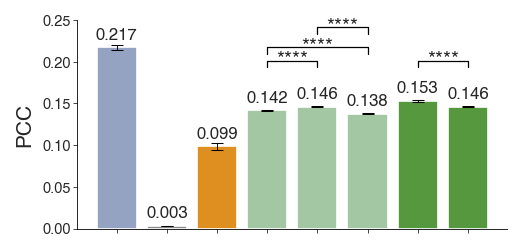

In [54]:
df = lincs_p_res.copy()

df_stats = (
    df.groupby('model')[['test_pearson', 'test_mse']]
      .agg(['mean','sem'])
      .reindex(model_order)
      .reset_index()
)
df_stats.columns = ['_'.join(col).strip('_') for col in df_stats.columns]

fig, ax = plt.subplots(figsize=(3.6, 1.8))

sns.barplot(data=df_stats, x='model', y='test_pearson_mean',
            order=model_order, palette=palette, ax=ax)

ax.errorbar(np.arange(len(df_stats)),
            df_stats['test_pearson_mean'],
            df_stats['test_pearson_sem'],
            fmt='none', ecolor='black', elinewidth=0.45, capsize=3, capthick=0.5)

for i, row in df_stats.iterrows():
    ax.text(i, row['test_pearson_mean'] + 0.006,
            f"{row['test_pearson_mean']:.3f}",
            ha='center', va='bottom', fontsize=8)

ax.set_ylabel("PCC", fontsize=10)
ax.set_xlabel('')
ax.set_ylim(0, 0.25)
ax.set_xticklabels(['' for m in model_order], rotation=30, ha='right')

ax.tick_params(axis='x', which='major', labelsize=10)
ax.tick_params(axis='y', which='major', labelsize=7)
ax.tick_params(width=0.4, length=2, direction='out', pad=1)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for spine in ax.spines.values():
    spine.set_linewidth(0.4)

y_base = df_stats['test_pearson_mean'].max() - 0.024
line_height = 0.008

for i, (m1, m2) in enumerate(pairs):
    p = compute_p(df, m1, m2, 'test_pearson')
    star = p_to_star(p)
    x1 = model_order.index(m1)
    x2 = model_order.index(m2)

    if i<3:
        y_base = y_base + i*0.008
    else:
        y_base = df_stats['test_pearson_mean'].max() - 0.048

    ax.plot([x1, x1, x2, x2],
             [y_base+i*line_height, y_base+(i+1)*line_height,
              y_base+(i+1)*line_height, y_base+i*line_height],
             color='black', linewidth=0.6)

    ax.text((x1 + x2) / 2, y_base+(i+1)*line_height - 0.01,
             star, ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

/tmp/ipykernel_922779/1589505047.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_stats, x='model', y='test_pearson_mean',
/tmp/ipykernel_922779/1589505047.py:29: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels([model_display[m] for m in model_order], rotation=30, ha='right')


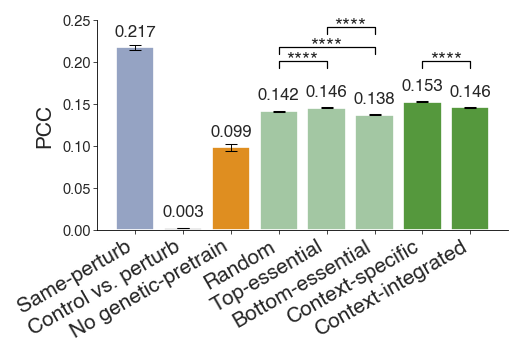

In [55]:
df = lincs_p_res.copy()

df_stats = (
    df.groupby('model')[['test_pearson', 'test_mse']]
      .agg(['mean','sem'])
      .reindex(model_order)
      .reset_index()
)
df_stats.columns = ['_'.join(col).strip('_') for col in df_stats.columns]

fig, ax = plt.subplots(figsize=(3.6, 2.5))

sns.barplot(data=df_stats, x='model', y='test_pearson_mean',
            order=model_order, palette=palette, ax=ax)

ax.errorbar(np.arange(len(df_stats)),
            df_stats['test_pearson_mean'],
            df_stats['test_pearson_sem'],
            fmt='none', ecolor='black', elinewidth=0.45, capsize=3, capthick=0.5)

for i, row in df_stats.iterrows():
    ax.text(i, row['test_pearson_mean'] + 0.01,
            f"{row['test_pearson_mean']:.3f}",
            ha='center', va='bottom', fontsize=8)

ax.set_ylabel("PCC", fontsize=10)
ax.set_xlabel('')
ax.set_ylim(0, 0.25)
ax.set_xticklabels([model_display[m] for m in model_order], rotation=30, ha='right')

ax.tick_params(axis='x', which='major', labelsize=10)
ax.tick_params(axis='y', which='major', labelsize=7)
ax.tick_params(width=0.4, length=2, direction='out', pad=1)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for spine in ax.spines.values():
    spine.set_linewidth(0.4)

y_base = df_stats['test_pearson_mean'].max() - 0.024
line_height = 0.008

for i, (m1, m2) in enumerate(pairs):
    p = compute_p(df, m1, m2, 'test_pearson')
    star = p_to_star(p)
    x1 = model_order.index(m1)
    x2 = model_order.index(m2)

    if i<3:
        y_base = y_base + i*0.008
    else:
        y_base = df_stats['test_pearson_mean'].max() - 0.048

    ax.plot([x1, x1, x2, x2],
             [y_base+i*line_height, y_base+(i+1)*line_height,
              y_base+(i+1)*line_height, y_base+i*line_height],
             color='black', linewidth=0.6)

    ax.text((x1 + x2) / 2, y_base+(i+1)*line_height - 0.01,
             star, ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

/tmp/ipykernel_922779/918263120.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_922779/918263120.py:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels([model_display[m] for m in model_order],
/tmp/ipykernel_922779/918263120.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_922779/918263120.py:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels([model_display[m] for m in model_order],
/tmp/ipykernel_922779/918263120.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hu

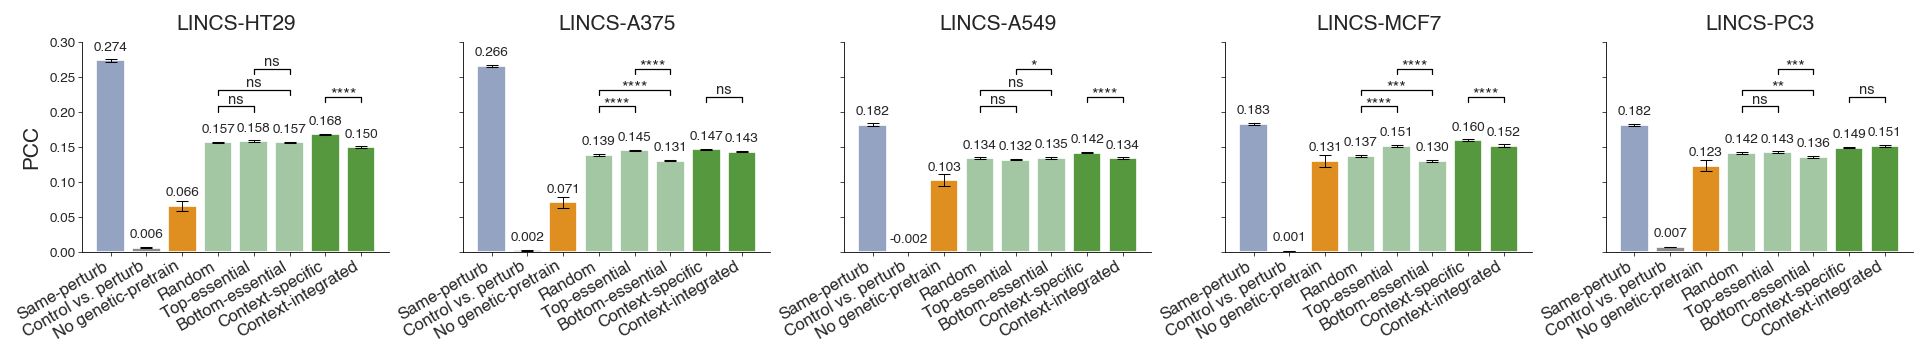

In [56]:
cell_lines = ['HT29', 'A375', 'A549', 'MCF7', 'PC3']

fig, axes = plt.subplots(1, len(cell_lines), figsize=(13, 2.5), sharey=True)

for ax, cell in zip(axes, cell_lines):

    df_cell = lincs_p_res[lincs_p_res['cell_line'] == cell]

    df_stats = (
        df_cell.groupby('model')[['test_pearson', 'test_mse']]
              .agg(['mean','sem'])
              .reindex(model_order)
              .reset_index()
    )
    df_stats.columns = ['_'.join(col).strip('_') for col in df_stats.columns]

    sns.barplot(
        data=df_stats,
        x='model', y='test_pearson_mean',
        order=model_order, palette=palette, ax=ax
    )

    ax.errorbar(np.arange(len(df_stats)),
                df_stats['test_pearson_mean'],
                df_stats['test_pearson_sem'],
                fmt='none', ecolor='black', elinewidth=0.45, capsize=3, capthick=0.5)

    for i, row in df_stats.iterrows():
        ax.text(i, row['test_pearson_mean'] + 0.01,
                f"{row['test_pearson_mean']:.3f}",
                ha='center', va='bottom', fontsize=6.5)

    ax.set_title(f"LINCS-{cell}", fontsize=10)
    ax.set_xlabel('')
    if ax is axes[0]:
        ax.set_ylabel('PCC', fontsize=10)
    else:
        ax.set_ylabel('')

    ax.set_ylim(0, 0.30)
    ax.set_xticklabels([model_display[m] for m in model_order],
                        rotation=30, ha='right')

    ax.tick_params(axis='x', which='major', labelsize=8)
    ax.tick_params(axis='y', which='major', labelsize=6.5)
    ax.tick_params(width=0.4, length=2, direction='out', pad=1)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for spine in ax.spines.values():
        spine.set_linewidth(0.4)

    y_base = 0.19
    line_height = 0.008

    for i, (m1, m2) in enumerate(pairs):
        p = compute_p(df_cell, m1, m2, 'test_pearson')
        star = p_to_star(p)
        font_s = 7 if star == 'ns' else 8
        font_h = 0 if star == 'ns' else 0.008

        x1 = model_order.index(m1)
        x2 = model_order.index(m2)

        if i<3:
            y_base = y_base + i*0.006 + 0.01
        else:
            y_base = 0.19

        ax.plot([x1, x1, x2, x2],
                [y_base+i*line_height, y_base+(i+1)*line_height,
                y_base+(i+1)*line_height, y_base+i*line_height],
                color='black', linewidth=0.6)

        ax.text((x1 + x2) / 2, y_base+(i+1)*line_height - font_h,
                star, ha='center', va='bottom', fontsize=font_s)

plt.tight_layout(w_pad=0.1)
plt.show()

## LINCS compound similarity-based finetune


In [121]:
import pandas as pd

lincs_simf_res = pd.read_csv('../G2CP/results/LINCS_compound_similarity_finetune_results.csv', index_col=0)
lincs_cpf_res = pd.read_csv('../G2CP/results/LINCS_cross_pretrain_finetune_results.csv', index_col=0)


In [ ]:
mapping_dict = {
    'pretrain-finetune-cpf': 'pretrain-finetune',
    'no-perturb-cpf': 'no-perturb',
    'ground-truth-cpf': 'ground-truth',
    'no-pretrain': 'no-pretrain',
}
lincs_cpf_res['model'] = lincs_cpf_res['model'].map(mapping_dict) 

lincs_cpf_res.loc[
    (lincs_cpf_res['pretrain_frac'] == 0.0) & (lincs_cpf_res['model'].str.contains('pretrain-finetune', case=False)),
    'model'
] = 'no-pretrain'


lincs_cpf_res.loc[
    (lincs_cpf_res['pretrain_frac'] == 1.0) & (lincs_cpf_res['model'].str.contains('pretrain-finetune', case=False)),
    'model'
] = 'full-pretrain'


In [135]:
lincs_simf_res.loc[
    (lincs_simf_res['pretrain_frac'] == 0.0) & (lincs_simf_res['model'].str.contains('pretrain-finetune-simf-fingerprint', case=False)),
    'model'
] = 'no-pretrain-simf-fingerprint'

lincs_simf_res.loc[
    (lincs_simf_res['pretrain_frac'] == 0.0) & (lincs_simf_res['model'].str.contains('pretrain-finetune-simf-butina', case=False)),
    'model'
] = 'no-pretrain-simf-butina'

lincs_simf_res.loc[
    (lincs_simf_res['pretrain_frac'] == 0.0) & (lincs_simf_res['model'].str.contains('pretrain-finetune-simf-scaffold', case=False)),
    'model'
] = 'no-pretrain-simf-scaffold'

In [136]:
filtered_cpf = lincs_cpf_res[lincs_cpf_res['pretrain_frac'].isin([0.0, 1.0])]
combined_lincs_simf_res = pd.concat([lincs_simf_res, filtered_cpf], ignore_index=True)

In [137]:
pd.crosstab(combined_lincs_simf_res['model'], combined_lincs_simf_res['finetune_frac'])

finetune_frac,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
model,,,,,,,,,
full-pretrain,25,25,25,25,25,25,25,25,25
ground-truth,25,25,25,25,25,25,25,25,25
ground-truth-simf-butina,25,25,25,25,25,25,25,25,25
ground-truth-simf-fingerprint,25,25,25,25,25,25,25,25,25
ground-truth-simf-scaffold,25,25,25,25,25,25,25,25,25
no-perturb,25,25,25,25,25,25,25,25,25
no-perturb-simf-butina,25,25,25,25,25,25,25,25,25
no-perturb-simf-fingerprint,25,25,25,25,25,25,25,25,25
no-perturb-simf-scaffold,25,25,25,25,25,25,25,25,25


In [138]:
len(combined_lincs_simf_res)

3600

### plot

In [139]:
df = combined_lincs_simf_res.copy()

def get_split(x):
    if 'butina' in x:
        return 'Butina'
    elif 'fingerprint' in x:
        return 'Fingerprint'
    elif 'scaffold' in x:
        return 'Scaffold'
    else:
        return 'Random'

df['Split Method'] = df.index.map(get_split) if 'model' not in df else df['model'].map(get_split)

df_pretrain = df[
    df['model'].str.contains('pretrain-finetune', case=False) |
    df['model'].str.contains('full-pretrain', case=False)
]
df_nopretrain = df[df['model'].str.contains('no-pretrain', case=False)]
df_gt = df[df['model'].str.contains('ground-truth', case=False)]
df_ctrl = df[df['model'].str.contains('no-perturb', case=False)]


In [140]:
pd.crosstab(df['Split Method'], df['cell_line'])

cell_line,A375,A549,HT29,MCF7,PC3
Split Method,,,,,
Butina,180,180,180,180,180
Fingerprint,180,180,180,180,180
Random,180,180,180,180,180
Scaffold,180,180,180,180,180


In [141]:
df.groupby(['Split Method', 'model']).mean(numeric_only = True)

test_mse  test_pearson  \
Split Method model                                                        
Butina       ground-truth-simf-butina            3.022508      0.221037   
             no-perturb-simf-butina              1.920639      0.003265   
             no-pretrain-simf-butina             1.921604      0.096811   
             pretrain-finetune-simf-butina       1.908931      0.153977   
Fingerprint  ground-truth-simf-fingerprint       2.916666      0.220958   
             no-perturb-simf-fingerprint         1.851454      0.003109   
             no-pretrain-simf-fingerprint        1.895537      0.086941   
             pretrain-finetune-simf-fingerprint  1.832581      0.149601   
Random       full-pretrain                       1.804858      0.153011   
             ground-truth                        2.912195      0.217395   
             no-perturb                          1.836127      0.003111   
             no-pretrain                         1.832462      0.098547   
Scaffold     ground-truth-simf-scaffold          2.958996      0.227547   
             no-perturb-simf-scaffold            1.837520      0.003295   
             no-pretrain-simf-scaffold           1.858302      0.091618   
             pretrain-finetune-simf-scaffold     1.811500      0.153885   

                                                  seed  pretrain_frac  \
Split Method model                                                      
Butina       ground-truth-simf-butina            734.8            0.0   
             no-perturb-simf-butina              734.8            0.0   
             no-pretrain-simf-butina             734.8            0.0   
             pretrain-finetune-simf-butina       734.8            1.0   
Fingerprint  ground-truth-simf-fingerprint       734.8            0.0   
             no-perturb-simf-fingerprint         734.8            0.0   
             no-pretrain-simf-fingerprint        734.8            0.0   
             pretrain-finetune-simf-fingerprint  734.8            1.0   
Random       full-pretrain                       734.8            1.0   
             ground-truth                        734.8            0.0   
             no-perturb                          734.8            0.0   
             no-pretrain                         734.8            0.0   
Scaffold     ground-truth-simf-scaffold          734.8            0.0   
             no-perturb-simf-scaffold            734.8            0.0   
             no-pretrain-simf-scaffold           734.8            0.0   
             pretrain-finetune-simf-scaffold     734.8            1.0   

                                                 finetune_frac  
Split Method model                                              
Butina       ground-truth-simf-butina                      0.5  
             no-perturb-simf-butina                        0.5  
             no-pretrain-simf-butina                       0.5  
             pretrain-finetune-simf-butina                 0.5  
Fingerprint  ground-truth-simf-fingerprint                 0.5  
             no-perturb-simf-fingerprint                   0.5  
             no-pretrain-simf-fingerprint                  0.5  
             pretrain-finetune-simf-fingerprint            0.5  
Random       full-pretrain                                 0.5  
             ground-truth                                  0.5  
             no-perturb                                    0.5  
             no-pretrain                                   0.5  
Scaffold     ground-truth-simf-scaffold                    0.5  
             no-perturb-simf-scaffold                      0.5  
             no-pretrain-simf-scaffold                     0.5  
             pretrain-finetune-simf-scaffold               0.5

In [142]:
def p_to_star(p):
    if p < 1e-4: return "****"
    elif p < 1e-3: return "***"
    elif p < 1e-2: return "**"
    elif p < 0.05: return "*"
    else: return "ns"

palette = {
    'Random': '#BFBFBF',     
    'Scaffold': '#FFB347',   
    'Fingerprint': '#FF8C42',
    'Butina': '#D55E00',     
}

/tmp/ipykernel_922779/481989510.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_922779/481989510.py:44: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(stats['Split Method'], rotation=45)
/tmp/ipykernel_922779/481989510.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_922779/481989510.py:44: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(stats['Split Method'], rotation=45)
/tmp/ipykernel_922779/481989510.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `l

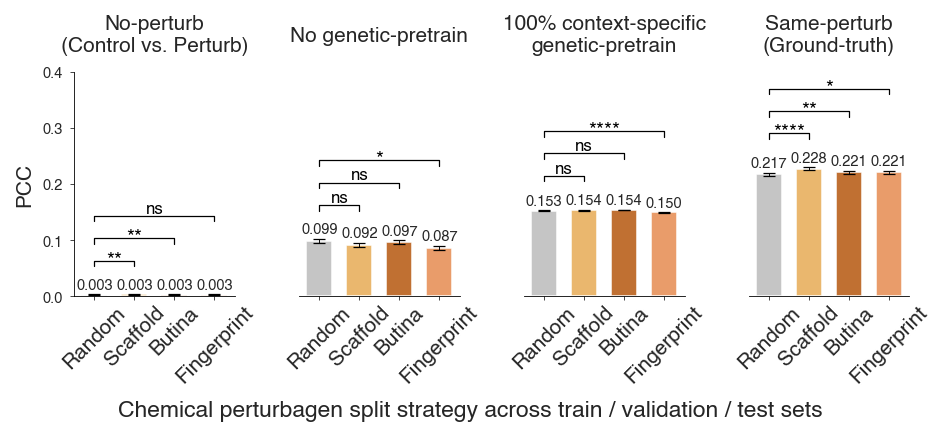

In [145]:
def plot_panel(ax, df, title, pad=15):
    stats = (
        df.groupby('Split Method')['test_pearson']
          .agg(['mean','sem'])
          .reindex(['Random','Scaffold','Butina','Fingerprint'])
          .reset_index()
    )

    sns.barplot(
        data=stats,
        x='Split Method', 
        y='mean',
        palette=palette,
        # edgecolor='black',
        # linewidth=0.6,
        width=0.65,
        ax=ax,
        alpha=0.9
    )

    ax.errorbar(
        np.arange(len(stats)),
        stats['mean'],
        stats['sem'],
        fmt='none',
        ecolor='black',
        elinewidth=0.45,
        capsize=3,
        capthick=0.6
    )

    for i, row in stats.iterrows():
        ax.text(
            i, row['mean'] + row['sem'] + 0.004,
            f"{row['mean']:.3f}",
            ha='center', va='bottom',
            fontsize=7
        )

    ax.set_title(title, fontsize=10, pad=pad)
    ax.set_xlabel('')
    ax.set_ylabel('PCC', fontsize=10)
    ax.set_ylim(0, 0.4)
    ax.set_xticklabels(stats['Split Method'], rotation=45)
    ax.tick_params(axis='x', labelsize=10, pad=1)
    ax.tick_params(axis='y', labelsize=7, width=0.4, length=2, direction='out')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for spine in ax.spines.values():
        spine.set_linewidth(0.4)

    pairs = [
        ("Random", "Scaffold"),
        ("Random", "Butina"),
        ("Random", "Fingerprint"),
    ]

    x_positions = {name: i for i, name in enumerate(stats['Split Method'])}
    y_base = stats['mean'].max() + stats['sem'].max() + 0.05
    step = 0.04  

    for k, (g1, g2) in enumerate(pairs):
        vals1 = df.loc[df['Split Method'] == g1, 'test_pearson']
        vals2 = df.loc[df['Split Method'] == g2, 'test_pearson']
        if len(vals1)==0 or len(vals2)==0:
            continue
        stat, p = wilcoxon(vals1, vals2, alternative='two-sided')
        star = p_to_star(p)

        x1, x2 = x_positions[g1], x_positions[g2]
        y = y_base + k * step

        ax.plot([x1, x1, x2, x2],
                [y, y+0.01, y+0.01, y],
                color='black', linewidth=0.6)
        if star == 'ns':
            ax.text((x1+x2)/2, y+0.01,
                    star, ha='center', va='bottom',
                    fontsize=8, color='black')
        else:
            ax.text((x1+x2)/2, y-0.005,
                    star, ha='center', va='bottom',
                    fontsize=10, color='black')

    sns.despine(ax=ax)


fig, axes = plt.subplots(1, 4, figsize=(6.5, 2.8), sharey=True)
axes = axes.flatten()

plot_panel(axes[0], df_ctrl, 'No-perturb\n(Control vs. Perturb)', 10)
plot_panel(axes[1], df_nopretrain, 'No genetic-pretrain')
plot_panel(axes[2], df_pretrain, '100% context-specific\ngenetic-pretrain', 10)
plot_panel(axes[3], df_gt, 'Same-perturb\n(Ground-truth)', 10)


for ax in axes[1:]:
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', left=False, labelleft=False)

for ax in axes[:]:
        ax.tick_params(axis='x', length=2, width=0.4)  
        
fig.text(0.5, 0.00, 'Chemical perturbagen split strategy across train / validation / test sets',
         ha='center', va='center', fontsize=11)

plt.tight_layout() 
fig.subplots_adjust(wspace=0.4, right=0.95) 
plt.show()

/tmp/ipykernel_922779/302381800.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_922779/302381800.py:43: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(stats['Split Method'], rotation=30)
/tmp/ipykernel_922779/302381800.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_922779/302381800.py:43: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(stats['Split Method'], rotation=30)
/tmp/ipykernel_922779/302381800.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set

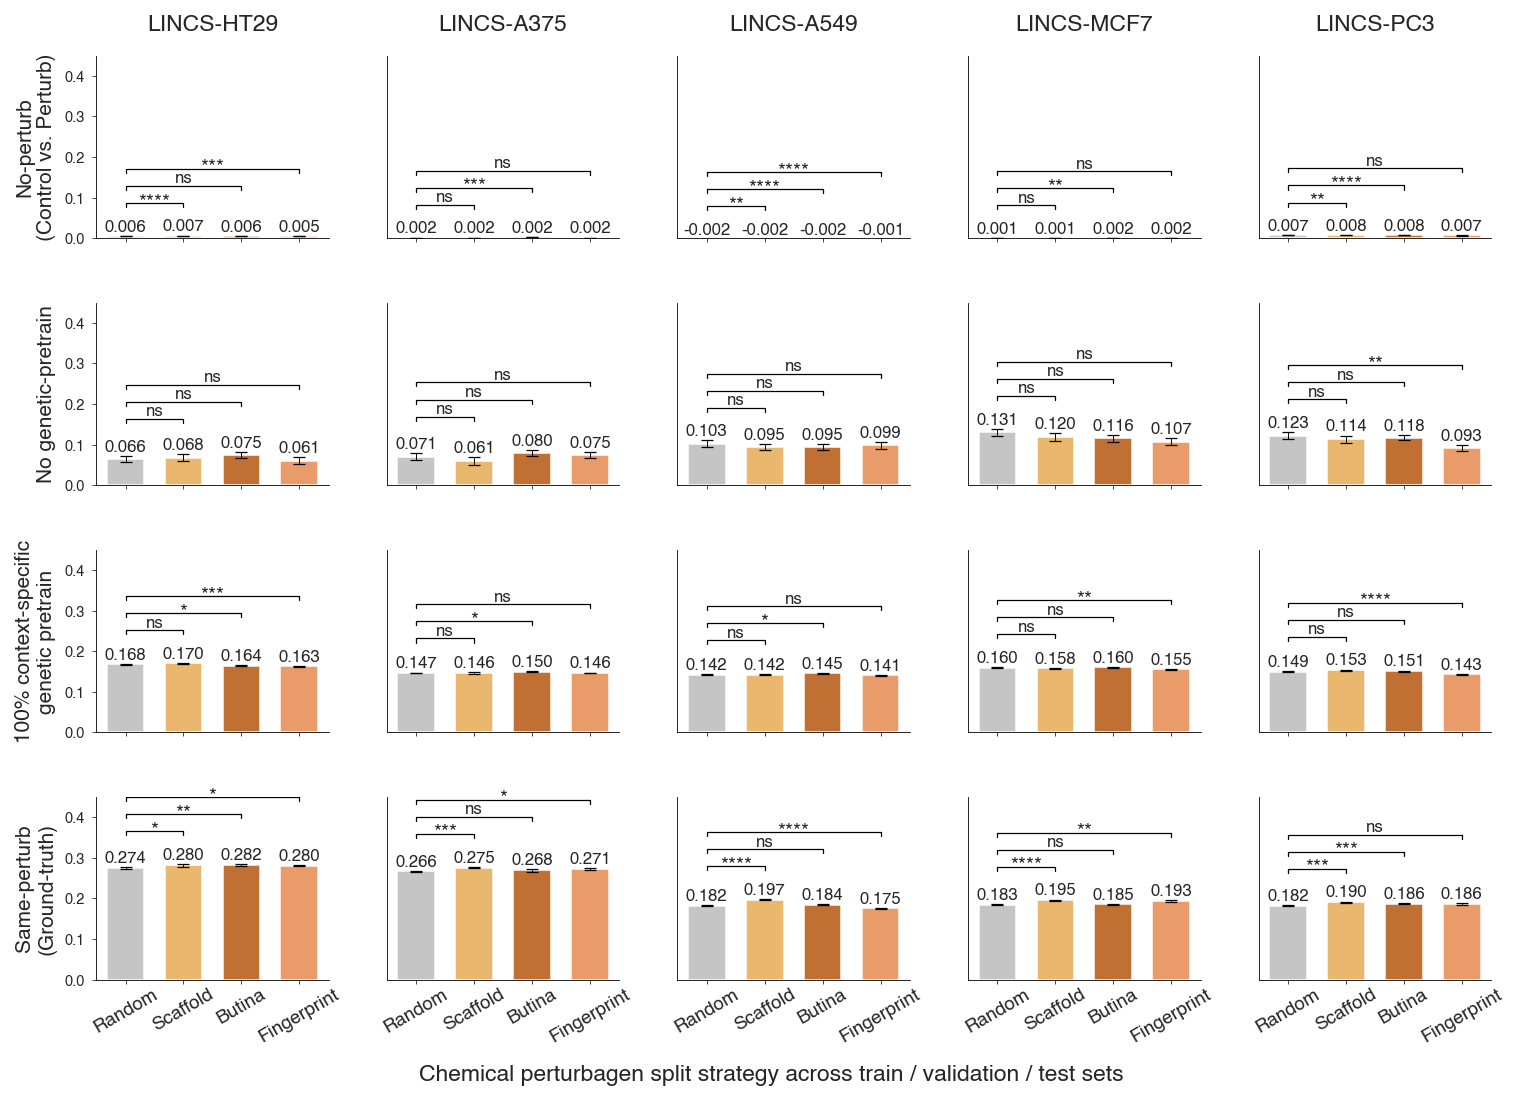

In [146]:
import re

def plot_panel(ax, df, title, pad=15):
    stats = (
        df.groupby('Split Method')['test_pearson']
          .agg(['mean','sem'])
          .reindex(['Random','Scaffold', 'Butina','Fingerprint'])
          .reset_index()
    )

    sns.barplot(
        data=stats,
        x='Split Method', 
        y='mean',
        palette=palette,
        width=0.65,
        ax=ax,
        alpha=0.9
    )

    ax.errorbar(
        np.arange(len(stats)),
        stats['mean'],
        stats['sem'],
        fmt='none',
        ecolor='black',
        elinewidth=0.45,
        capsize=3,
        capthick=0.6
    )

    for i, row in stats.iterrows():
        ax.text(
            i, row['mean'] + row['sem'] + 0.004,
            f"{row['mean']:.3f}",
            ha='center', va='bottom',
            fontsize=8
        )

    ax.set_title(title, fontsize=10, pad=pad+10)
    ax.set_xlabel('')
    ax.set_ylim(0, 0.45)
    ax.set_xticklabels(stats['Split Method'], rotation=30)
    ax.tick_params(axis='x', labelsize=9, pad=1, length=2, width=0.4)
    ax.tick_params(axis='y', labelsize=7, width=0.4, length=2, direction='out')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for spine in ax.spines.values():
        spine.set_linewidth(0.4)

    pairs = [
        ("Random", "Scaffold"),
        ("Random", "Butina"),
        ("Random", "Fingerprint"),
    ]

    x_positions = {name: i for i, name in enumerate(stats['Split Method'])}
    y_base = stats['mean'].max() + stats['sem'].max() + 0.07
    step = 0.042

    for k, (g1, g2) in enumerate(pairs):
        vals1 = df.loc[df['Split Method'] == g1, 'test_pearson']
        vals2 = df.loc[df['Split Method'] == g2, 'test_pearson']
        if len(vals1)==0 or len(vals2)==0:
            continue
        stat, p = wilcoxon(vals1, vals2, alternative='two-sided')
        star = p_to_star(p)

        x1, x2 = x_positions[g1], x_positions[g2]
        y = y_base + k * step

        ax.plot([x1, x1, x2, x2],
                [y, y+0.01, y+0.01, y],
                color='black', linewidth=0.6)
        if star == 'ns':
            ax.text((x1+x2)/2, y+0.01,
                    star, ha='center', va='bottom',
                    fontsize=8)
        else:
            ax.text((x1+x2)/2, y-0.01,
                    star, ha='center', va='bottom',
                    fontsize=10)

    sns.despine(ax=ax)


cell_lines = ['HT29', 'A375', 'A549', 'MCF7', 'PC3']
conditions = [
    ("No-perturb\n(Control vs. Perturb)", 'no-perturb'),
    ("No genetic-pretrain", 'no-pretrain'),
    ("100% context-specific\ngenetic pretrain", '(pretrain[-_]?finetune|full[-_]?pretrain)'),
    ("Same-perturb\n(Ground-truth)", 'ground-truth'),
]

fig, axes = plt.subplots(len(conditions), len(cell_lines), figsize=(12,8), sharey=True)

for row_i, (title, pattern) in enumerate(conditions):
    for col_j, cell in enumerate(cell_lines):

        df_cell = df[df['cell_line'] == cell]

        df_cond = df_cell[df_cell['model'].str.contains(pattern, flags=re.IGNORECASE, regex=True)]

        plot_panel(axes[row_i, col_j], df_cond, title, pad=5)

        if col_j == 0:
            axes[row_i, col_j].set_ylabel(title, fontsize=10)
        else:
            axes[row_i, col_j].set_ylabel("")
            axes[row_i, col_j].tick_params(axis='y', left=False, labelleft=False)

        if row_i == 0:
            axes[row_i, col_j].set_title('LINCS-'+cell, fontsize=11, pad=12)
        else:
            axes[row_i, col_j].set_title("")

        if row_i < len(conditions)-1:
            axes[row_i, col_j].set_xticklabels([])

fig.text(0.5, 0.03,
         'Chemical perturbagen split strategy across train / validation / test sets',
         ha='center', va='center', fontsize=11)

fig.subplots_adjust(wspace=0.25, hspace=0.35)
plt.show()